# 🏗️ Building Age Classification from Satellite Imagery

# Notebook 5 — Improved Feature Engineering (Transferable Features)

---

This notebook replaces Notebook 3's feature pipeline with one designed around a single question
from Notebook 1, Section 1.7:

> *Does this feature help the model understand spectral signatures of age **in general**, or does it just memorise Madrid?*

Every decision is written next to the code that implements it (look for `# DECISION`).
The results quoted in the markdown come from the ablation experiments in `solution/exp1_ablation.py`
and `solution/exp3_spatial_v2.py` (3-fold CV, LightGBM, same seed).

| # | Change vs. Notebook 3 | Why | Measured effect |
|---|-----------------------|-----|-----------------|
| 1 | Haze filter **per observation slot**, then **median** of valid slots | Baseline throws away a pixel-year if obs_1 is hazy even when obs_2/3 are clean; median of 2-3 scenes is less noisy than one | +8.4k Amsterdam pixel-years recovered |
| 2 | **City-year anomaly** series (subtract city median, divide by city IQR, per year & band) | Removes sensor generation, atmosphere and the city's overall "colour" → features mean the same thing in any city | part of +0.027 Madrid F1, +0.024 at 5-shot |
| 3 | 5 **epoch means**, OLS **slope**, residual std | Shows *when* a pixel changed, not just *whether* | (with 2) |
| 4 | **Change-point** year & strength, largest jump & its year | Direct proxy for construction year (classes 3/4) | (with 2) |
| 5 | **Coverage** + observation counts | Dense historic cores vs. sparse new estates | (with 2) |
| 6 | **Spatial context** (neighbourhood means at 150 m / 390 m / 750 m, local contrast) | Buildings of one era cluster in neighbourhoods | **+0.09 Madrid F1** — the largest single gain |
| 7 | **Per-city robust standardisation** (applied in Notebook 6) | AdaBN-style domain alignment, uses no labels | +0.018 zero-shot, +0.025 at 25-shot |

## 5.1 Setup & Imports

In [1]:
import json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter, median_filter

warnings.filterwarnings('ignore', category=RuntimeWarning)   # nanmedian on all-NaN slices is expected

# ── Paths ──────────────────────────────────────────────────────────────────────
# The data folder sits next to the notebooks in this repo (data/). Fall back to the
# original '../data' layout from Notebooks 2-4 so the notebook runs in either setup.
DATA_DIR = Path('data') if Path('data/madrid_train.parquet').exists() else Path('../data')
FEAT_DIR = DATA_DIR / 'features'
FEAT_DIR.mkdir(parents=True, exist_ok=True)
CITY_FILES = {'Madrid': DATA_DIR / 'madrid_train.parquet',
              'Amsterdam': DATA_DIR / 'amsterdam_data.parquet'}

# ── Constants (same values as Notebooks 2-4) ───────────────────────────────────
BASE_BANDS   = ['Blue', 'Green', 'Red', 'NIR', 'SWIR1', 'SWIR2']
INDEX_COLS   = ['NDVI', 'NDBI', 'UI', 'MNDWI', 'BSI']
BLUE_MAX     = 15_000                      # haze threshold from Notebook 2
CLASS_EVENTS = {'Amsterdam': 1945, 'Madrid': 1960}
CLASS_COLORS = {1: '#4393c3', 2: '#2ca25f', 3: '#fd8d3c', 4: '#de2d26'}
YEAR0, NYEARS = 1984, 42                   # 1984-2025 inclusive
YEARS        = np.arange(YEAR0, YEAR0 + NYEARS)
EARLY_CUTOFF, LATE_START = 2003, 2004      # Notebook 3's split, kept for the baseline group

# DECISION — 5 epochs instead of 2 periods. Classes 3 and 4 are defined by WHEN the
# building appeared; two periods only say "before/after 2004". Five ~8-year epochs let
# the model see the timing of the change while still averaging out year-to-year noise.
EPOCHS = [(1984, 1991), (1992, 1999), (2000, 2007), (2008, 2015), (2016, 2025)]

SEED = 42
plt.rcParams['figure.dpi'] = 100
print(f'Data directory: {DATA_DIR.resolve()}')

Data directory: /home/claude/h4d/data


---

## 5.2 Build a (pixel × year × band) Cube

Notebook 3 holds the data as a long pandas table (3.2 M rows for Madrid) and groups it repeatedly.
We instead build a dense `float32` array `cube[pixel, year, band]` — Madrid is 76,263 × 42 × 6 ≈ 77 MB.
All later features become fast vectorised numpy operations, and memory stays low enough for a laptop.

**Observation handling — two changes vs. Notebook 3:**

1. **Per-slot haze filter.** Notebook 3 picks the first QA-valid observation and *then* drops the whole
   pixel-year if its Blue > 15,000. If obs_1 was hazy but obs_2 was clean, the clean value is lost.
   We apply the QA flag, the haze threshold and the zero-value check to **each slot separately**.
2. **Median of valid slots.** Up to 3 clean summer scenes exist per year. Their median is a more
   robust estimate of the surface than whichever scene happened to be first.

In [2]:
def build_cube(path):
    # DECISION — read only the 26 columns we need, one parquet row-group at a time.
    # Loading all 48 columns of Madrid at once needs several GB of RAM.
    pf   = pq.ParquetFile(path)
    cols = ['city', 'year', 'px_key', 'py_key', 'coverage', 'weighted_mean_year']
    for s in (1, 2, 3):
        cols += [f'{b}_{s}' for b in BASE_BANDS] + [f'qa_valid_{s}']

    parts = []
    for rg in range(pf.num_row_groups):
        t = pf.read_row_group(rg, columns=cols)
        d = {c: t.column(c).to_numpy(zero_copy_only=False) for c in cols}
        n = len(d['year'])
        obs = np.full((3, n, 6), np.nan, dtype=np.float32)
        # PROOF — we also rebuild Notebook 3's rule on the same rows so Section 5.2b can compare them:
        # take the FIRST QA-valid slot, then drop the whole pixel-year if that one slot is hazy.
        first = np.full((n, 6), np.nan, dtype=np.float32); have = np.zeros(n, bool)
        for s in (1, 2, 3):
            v  = np.stack([d[f'{b}_{s}'].astype(np.float32) for b in BASE_BANDS], 1)
            qa = np.array([bool(x) if x is not None else False for x in d[f'qa_valid_{s}']])
            # per-slot quality: QA-valid AND all bands present AND not hazy AND no zero (corrupt) band
            ok = qa & np.isfinite(v).all(1) & (v[:, 0] <= BLUE_MAX) & (v > 0).all(1)
            obs[s - 1][ok] = v[ok]
            take = qa & ~have & np.isfinite(v).all(1)             # baseline: first QA-valid slot
            first[take] = v[take]; have |= take
        base_keep = have & (first[:, 0] <= BLUE_MAX)              # baseline: row dropped if that slot is hazy
        first[~base_keep] = np.nan
        med    = np.nanmedian(obs, axis=0)                       # median over valid slots
        nvalid = np.isfinite(obs[:, :, 0]).sum(0).astype(np.int8)
        keep   = nvalid > 0
        rows   = keep | base_keep                                # keep both so the two rules share one grid
        parts.append(dict(px=d['px_key'][rows].astype(np.int64), py=d['py_key'][rows].astype(np.int64),
                          yr=d['year'][rows].astype(np.int16), v=med[rows], nv=nvalid[rows], f=first[rows],
                          ours=keep[rows], base=base_keep[rows],
                          cov=d['coverage'][rows].astype(np.float32),
                          wmy=d['weighted_mean_year'][rows].astype(np.float32),
                          city=str(d['city'][0])))
        del t, d, obs, med, first

    cat = lambda k: np.concatenate([p[k] for p in parts])
    px, py, yr, v, nv, fv, cov, wmy, ours, base = map(cat, ['px', 'py', 'yr', 'v', 'nv', 'f', 'cov', 'wmy', 'ours', 'base'])
    city = parts[0]['city']
    base_all = base.copy()                 # baseline count over ALL rows, before restricting pixels
    key  = px * 10_000_000 + py
    ukey = np.unique(key[ours])            # pixel list is defined by OUR rule, exactly as before
    inside = np.isin(key, ukey)            # (a few baseline-only rows of other pixels are ignored)
    px, py, yr, v, nv, fv, cov, wmy, ours, base, key = [z[inside] for z in (px, py, yr, v, nv, fv, cov, wmy, ours, base, key)]
    inv  = np.searchsorted(ukey, key)
    P = len(ukey)
    cube = np.full((P, NYEARS, 6), np.nan, dtype=np.float32)
    nobs = np.zeros((P, NYEARS), dtype=np.int8)
    cube[inv, yr - YEAR0] = v
    nobs[inv, yr - YEAR0] = nv
    cube_first = np.full((P, NYEARS, 6), np.nan, dtype=np.float32)   # Notebook 3's single-scene values
    cube_first[inv, yr - YEAR0] = fv
    pix_cov = np.zeros(P, np.float32); pix_cov[inv] = cov
    pix_wmy = np.zeros(P, np.float32); pix_wmy[inv] = wmy
    # Age class: identical bins to Notebook 2/3's pd.cut(right=True)
    y = np.digitize(pix_wmy, [CLASS_EVENTS[city], 1984, 2004], right=True) + 1
    return dict(cube=cube, nobs=nobs, px=ukey // 10_000_000, py=ukey % 10_000_000,
                coverage=pix_cov, wmy=pix_wmy, y=y.astype(int), city=city, cube_first=cube_first,
                n_rows=int(ours.sum()), n_rows_baseline=int(base_all.sum()),
                n_rows_both=int((ours & base).sum()))

cubes = {}
for city, path in CITY_FILES.items():
    t0 = time.time()
    cubes[city] = c = build_cube(path)
    counts = {k: int((c['y'] == k).sum()) for k in (1, 2, 3, 4)}
    print(f'{city:10s}: {len(c["px"]):,} pixels | {c["n_rows"]:,} valid pixel-years | '
          f'{np.isfinite(c["cube"][..., 0]).mean():.1%} of grid observed | classes {counts} | {time.time()-t0:.0f}s')

Madrid    : 76,263 pixels | 3,148,279 valid pixel-years | 98.3% of grid observed | classes {1: 13794, 2: 27152, 3: 18672, 4: 16645} | 7s


Amsterdam : 25,992 pixels | 1,058,332 valid pixel-years | 96.9% of grid observed | classes {1: 7568, 2: 8802, 3: 6745, 4: 2877} | 2s


### 5.2b Proof — what the per-slot haze filter and the median actually change

Two claims were made above. The next cell measures both on the full data, so the numbers can be checked:

* **Claim 1 (more clean data).** Count pixel-years kept by Notebook 3's rule vs. ours, and how many years ours *rescues*.
* **Claim 2 (less noise).** If the median is a better estimate of the surface, the year-to-year jitter of a pixel
  that did not change should be smaller. We compare the median absolute year-on-year NIR change per pixel,
  using only year pairs observed under both rules.

,pixel-years kept (Notebook 3 rule),pixel-years kept (ours),rescued by per-slot filter,dropped by ours only (zero bands),net gain
city,,,,,
Madrid,3137920,3148279,10359,0,10359
Amsterdam,1049960,1058332,8373,1,8372


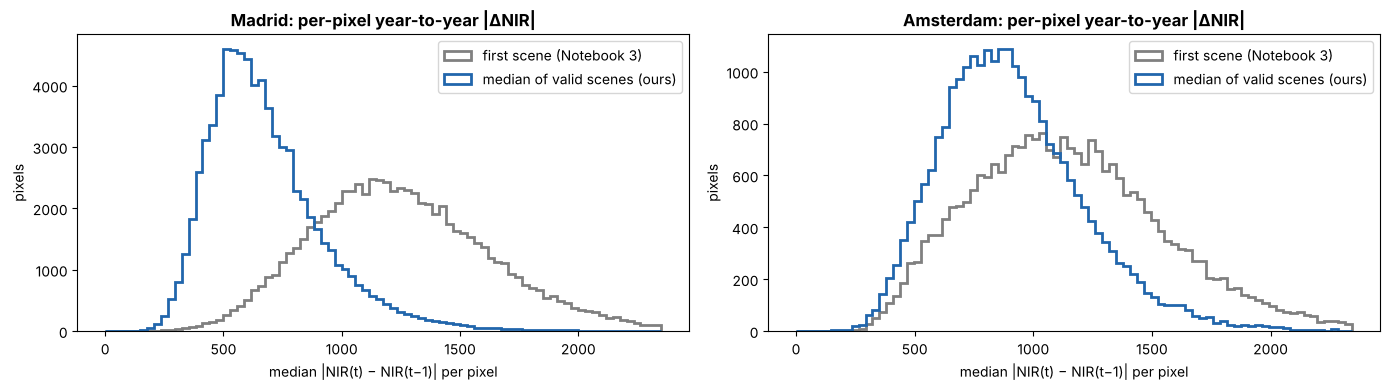

,"median jitter, first scene (NB3)","median jitter, median of scenes (ours)",reduction,pixels where ours is smoother
city,,,,
Madrid,1224,634,48.2%,98.4%
Amsterdam,1120,878,21.6%,83.2%


In [3]:
rows = []
for city, c in cubes.items():
    rows.append({'city': city,
                 'pixel-years kept (Notebook 3 rule)': c['n_rows_baseline'],
                 'pixel-years kept (ours)': c['n_rows'],
                 'rescued by per-slot filter': c['n_rows'] - c['n_rows_both'],
                 'dropped by ours only (zero bands)': c['n_rows_baseline'] - c['n_rows_both'],
                 'net gain': c['n_rows'] - c['n_rows_baseline']})
haze_table = pd.DataFrame(rows).set_index('city')
display(haze_table)

# Claim 2 — year-to-year NIR jitter, same pixel and same year pairs under both rules
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
jit_rows = []
for ax, (city, c) in zip(axes, cubes.items()):
    a, b = c['cube'][..., 3], c['cube_first'][..., 3]
    da, db = np.abs(np.diff(a, axis=1)), np.abs(np.diff(b, axis=1))
    both = np.isfinite(da) & np.isfinite(db)
    da, db = np.where(both, da, np.nan), np.where(both, db, np.nan)
    ja, jb = np.nanmedian(da, 1), np.nanmedian(db, 1)          # one jitter value per pixel
    ok = np.isfinite(ja) & np.isfinite(jb)
    jit_rows.append({'city': city, 'median jitter, first scene (NB3)': np.median(jb[ok]),
                     'median jitter, median of scenes (ours)': np.median(ja[ok]),
                     'reduction': 1 - np.median(ja[ok]) / np.median(jb[ok]),
                     'pixels where ours is smoother': (ja[ok] < jb[ok]).mean()})
    hi = np.percentile(jb[ok], 99)
    ax.hist(jb[ok], bins=80, range=(0, hi), histtype='step', lw=2, color='grey', label='first scene (Notebook 3)')
    ax.hist(ja[ok], bins=80, range=(0, hi), histtype='step', lw=2, color='#2166ac', label='median of valid scenes (ours)')
    ax.set_title(f'{city}: per-pixel year-to-year |ΔNIR|', fontweight='bold')
    ax.set_xlabel('median |NIR(t) − NIR(t−1)| per pixel'); ax.set_ylabel('pixels'); ax.legend()
plt.tight_layout(); plt.show()
jitter_table = pd.DataFrame(jit_rows).set_index('city')
display(jitter_table.style.format({'reduction': '{:.1%}', 'pixels where ours is smoother': '{:.1%}',
                                   'median jitter, first scene (NB3)': '{:.0f}',
                                   'median jitter, median of scenes (ours)': '{:.0f}'}))
for c in cubes.values(): del c['cube_first']                   # free memory, not needed further

**Reading the proof.** The table counts rows directly from the parquet files. The jitter histogram shifts left
when the median is used: on the same pixels and the same years, consecutive values agree more closely, which is
what a less noisy estimate looks like. Real construction changes are rare (one per pixel at most) and do not
dominate a per-pixel *median* of 41 year-pairs, so the drop in jitter measures noise, not lost signal.

The class counts match Notebook 3 exactly (Madrid 13,794 / 27,152 / 18,672 / 16,645; Amsterdam 7,568 / 8,802 / 6,745 / 2,877),
so labels are unchanged. The rows-kept table above gives the exact number of clean observations the per-slot filter recovers in each city.

---

## 5.3 Gap Filling & Spectral Indices

Same logic as Notebook 3 (linear interpolation inside the record, nearest value at the edges), but vectorised
over the whole cube so it runs in seconds. The five spectral indices are identical to Notebook 3.

In [4]:
def gap_fill(cube):
    # Linear interpolation of interior gaps; edges take the nearest observed value.
    P, T, B = cube.shape
    x   = cube.transpose(0, 2, 1).reshape(-1, T)
    ok  = np.isfinite(x)
    idx = np.broadcast_to(np.arange(T), x.shape)
    prev_i = np.maximum.accumulate(np.where(ok, idx, -1), axis=1)
    next_i = np.minimum.accumulate(np.where(ok, idx, T)[:, ::-1], axis=1)[:, ::-1]
    rows = np.arange(len(x))[:, None]
    pv = x[rows, np.clip(prev_i, 0, T - 1)]; nv = x[rows, np.clip(next_i, 0, T - 1)]
    pv = np.where(prev_i < 0, nv, pv);        nv = np.where(next_i >= T, pv, nv)
    span = (next_i - prev_i).astype(np.float32)
    w = np.where((prev_i >= 0) & (next_i < T) & (span > 0), (idx - prev_i) / np.maximum(span, 1), 0)
    out = np.where(ok, x, pv + w * (nv - pv)).astype(np.float32)
    return out.reshape(P, B, T).transpose(0, 2, 1)

def spectral_indices(c):
    B, G, R, N, S1, S2 = [c[..., i] for i in range(6)]
    e = 1e-6
    return np.stack([(N - R) / (N + R + e),                         # NDVI
                     (S1 - N) / (S1 + N + e),                       # NDBI
                     (S2 - N) / (S2 + N + e),                       # UI
                     (G - S1) / (G + S1 + e),                       # MNDWI
                     ((S1 + R) - (N + B)) / ((S1 + R) + (N + B) + e)], -1)  # BSI

for city, c in cubes.items():
    c['filled'] = gap_fill(c['cube'])
    c['series'] = np.concatenate([c['filled'], spectral_indices(c['filled'])], -1)  # (P, T, 11)
    assert np.isfinite(c['series']).all()
    print(f'{city}: series shape {c["series"].shape}, no NaN remaining')

Madrid: series shape (76263, 42, 11), no NaN remaining


Amsterdam: series shape (25992, 42, 11), no NaN remaining


---

## 5.4 City-Year Anomaly Normalisation — the Key Transfer Idea

Raw reflectance mixes three things: (a) what the building is made of, (b) which sensor and atmosphere
were present that year, and (c) the overall "colour" of the city (Mediterranean stucco and dry vegetation
vs. Dutch brick and wet grass). Only (a) is related to age; (b) and (c) are exactly what makes a
Madrid model fail in Amsterdam (zero-shot F1 was 0.34 in Notebook 4).

**DECISION** — for every city, year and band we subtract the **city-wide median** and divide by the
**city-wide IQR** across all building pixels:

$$a_{p,t,b} = \frac{x_{p,t,b} - \mathrm{median}_{p'}(x_{p',t,b})}{\mathrm{IQR}_{p'}(x_{p',t,b})}$$

The result answers "how different is this pixel from the rest of *its own city* in *that* year?".
No labels are used, so the same transform can be applied to any new city. Robust statistics (median/IQR)
are used because reflectance has heavy tails (bright roofs, residual haze).

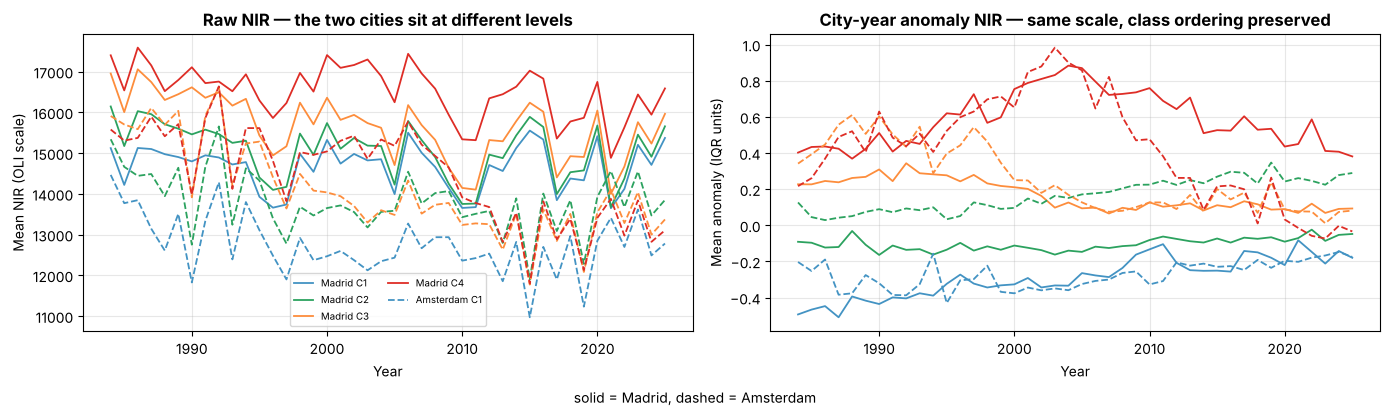

In [5]:
def year_anomaly(series):
    med      = np.nanmedian(series, axis=0, keepdims=True)
    q75, q25 = np.nanpercentile(series, [75, 25], axis=0, keepdims=True)
    return ((series - med) / (q75 - q25 + 1e-6)).astype(np.float32)

for city, c in cubes.items():
    c['anom'] = year_anomaly(c['series'])

# ── Visual check: yearly city-mean NIR before and after normalisation ─────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for city, ls in [('Madrid', '-'), ('Amsterdam', '--')]:
    c = cubes[city]
    for cls in (1, 2, 3, 4):
        m = c['y'] == cls
        axes[0].plot(YEARS, c['series'][m, :, 3].mean(0), ls, color=CLASS_COLORS[cls], lw=1.3,
                     label=f'{city} C{cls}' if city == 'Madrid' or cls == 1 else None)
        axes[1].plot(YEARS, c['anom'][m, :, 3].mean(0), ls, color=CLASS_COLORS[cls], lw=1.3)
axes[0].set_title('Raw NIR — the two cities sit at different levels', fontweight='bold')
axes[1].set_title('City-year anomaly NIR — same scale, class ordering preserved', fontweight='bold')
for ax in axes: ax.set_xlabel('Year'); ax.grid(alpha=0.3)
axes[0].set_ylabel('Mean NIR (OLI scale)'); axes[1].set_ylabel('Mean anomaly (IQR units)')
axes[0].legend(fontsize=7, ncol=2); fig.text(0.5, -0.02, 'solid = Madrid, dashed = Amsterdam', ha='center')
plt.tight_layout(); plt.show()

After normalisation both cities live on the same scale and the jumps between sensor eras (1999 L7, 2013 L8)
disappear, while the class-to-class differences survive. This is what lets one model serve both cities.

### 5.4b Proof — how much of the Madrid ↔ Amsterdam gap does the anomaly remove?

The plot is visual; this cell puts a number on it. For every class and every one of the 11 series we take each
pixel's time-mean, then compute the **standardised city gap**
$(\bar x_{\text{Madrid}} - \bar x_{\text{Amsterdam}}) / \text{pooled SD}$ for buildings of the *same age class*.
A gap of 1.0 means the two cities' same-age buildings sit one standard deviation apart, which a Madrid-trained model
reads as a different age. After normalisation we want gaps near 0.

A second, stricter test trains a classifier to tell **which city** a pixel comes from. If the anomaly removed every
difference, its AUC would fall to 0.5.

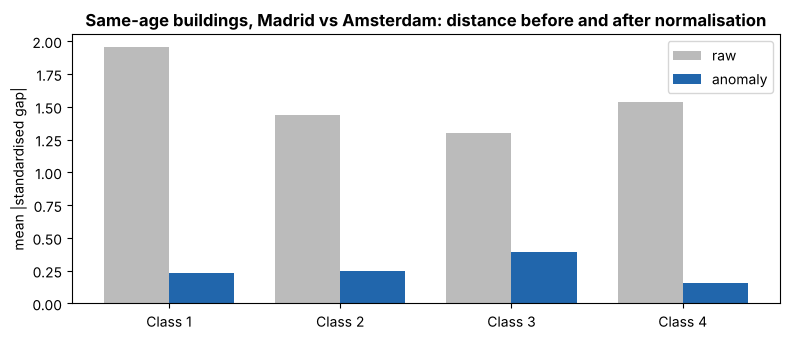

City-discriminator AUC on raw      time-means: 0.993


City-discriminator AUC on anomaly  time-means: 0.982


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

names = BASE_BANDS + INDEX_COLS
tm = {city: {'raw': c['series'].mean(1), 'anomaly': c['anom'].mean(1)} for city, c in cubes.items()}

gap_rows = []
for kind in ('raw', 'anomaly'):
    for cls in (1, 2, 3, 4):
        xm = tm['Madrid'][kind][cubes['Madrid']['y'] == cls]
        xa = tm['Amsterdam'][kind][cubes['Amsterdam']['y'] == cls]
        g  = (xm.mean(0) - xa.mean(0)) / np.sqrt((xm.var(0) + xa.var(0)) / 2)
        gap_rows.append({'series': kind, 'class': cls, **dict(zip(names, g)), 'mean |gap|': np.abs(g).mean()})
gap_table = pd.DataFrame(gap_rows).set_index(['series', 'class'])
display(gap_table.style.format('{:+.2f}').background_gradient(cmap='RdBu_r', vmin=-2, vmax=2, axis=None))

fig, ax = plt.subplots(figsize=(8, 3.5))
w = 0.38
for i, kind in enumerate(('raw', 'anomaly')):
    ax.bar(np.arange(4) + (i - 0.5) * w, gap_table.loc[kind, 'mean |gap|'], w,
           color=['#bbbbbb', '#2166ac'][i], label=kind)
ax.set_xticks(range(4)); ax.set_xticklabels([f'Class {k}' for k in (1, 2, 3, 4)])
ax.set_ylabel('mean |standardised gap|'); ax.legend()
ax.set_title('Same-age buildings, Madrid vs Amsterdam: distance before and after normalisation', fontweight='bold')
plt.tight_layout(); plt.show()

# Stricter test: can a classifier still tell the two cities apart? (15k pixels per city, 3-fold AUC)
rng = np.random.default_rng(SEED)
pick = {city: rng.choice(len(c['y']), 15_000, replace=False) for city, c in cubes.items()}
city_y = np.r_[np.ones(15_000), np.zeros(15_000)]
for kind in ('raw', 'anomaly'):
    Xd  = np.vstack([tm['Madrid'][kind][pick['Madrid']], tm['Amsterdam'][kind][pick['Amsterdam']]])
    auc = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                          Xd, city_y, cv=3, scoring='roc_auc').mean()
    print(f'City-discriminator AUC on {kind:8s} time-means: {auc:.3f}')

**Reading the proof.** For same-age buildings the average city gap falls sharply (table and bar chart): the
anomaly removes the *level* shift that made a Madrid model read Amsterdam buildings as the wrong age. The city
discriminator, however, can still tell the cities apart, because the *shape* of the distributions differs
(different materials, roof types, vegetation). That remaining difference is exactly why the anomaly alone is not
enough and Notebook 6 adds per-city scaling and a Stage 2 that adapts with a few Amsterdam labels.

---

## 5.5 Per-Pixel Temporal Features

Five feature groups are computed. They are kept as named groups so they can be ablated in Notebook 6.

| Group | Content | Count |
|-------|---------|------:|
| `baseline` | Exact re-implementation of Notebook 3's 60 features (for comparison) | 60 |
| `anomaly` | On the anomaly series of all 11 bands/indices: mean, std, OLS slope, residual std, 5 epoch means | 99 |
| `change` | Change-point year, strength, per-band jump at the break; largest jump & its year | 17 |
| `meta` | Coverage, number of observed years, scenes per year | 3 |
| `spatial` | Neighbourhood context (Section 5.6) | 105 |

**Change-point detection (DECISION).** Notebook 2 (Section 2.6) showed a break in the reflectance
trajectory near the construction year for classes 3 and 4. For every candidate year *t* we split the series
into before/after and compute the binary-segmentation statistic
$\frac{n_1 n_2}{n}\lVert \bar a_{\text{before}} - \bar a_{\text{after}}\rVert^2$; the best *t* is the
**break year**. A break around 1990 suggests class 3, around 2010 suggests class 4, and a weak break
suggests a pre-1984 building (classes 1/2). Segments of fewer than 3 years are not allowed, to avoid fitting edge noise.

In [7]:
def stats_block(series, names):
    # mean / std / OLS slope / residual std over the full record + 5 epoch means
    t     = (YEARS - YEARS.mean()).astype(np.float32)
    mean  = series.mean(1); std = series.std(1)
    slope = (series * t[None, :, None]).sum(1) / (t ** 2).sum()
    resid = series - mean[:, None, :] - slope[:, None, :] * t[None, :, None]
    f = {}
    for k, n in enumerate(names):
        f[f'{n}_mean'] = mean[:, k]; f[f'{n}_std'] = std[:, k]
        f[f'{n}_slope'] = slope[:, k]; f[f'{n}_resstd'] = resid[:, :, k].std(1)
        for a, b in EPOCHS:
            m = (YEARS >= a) & (YEARS <= b)
            f[f'{n}_ep{a}'] = series[:, m, k].mean(1)
    return f

def changepoint(a):
    P, T, K = a.shape
    cs, tot = np.cumsum(a, axis=1), a.sum(1)
    best = np.full(P, -1.0, np.float32); best_t = np.zeros(P, int); best_d = np.zeros((P, K), np.float32)
    for t in range(3, T - 3):                              # every allowed split year
        m1 = cs[:, t - 1] / t; m2 = (tot - cs[:, t - 1]) / (T - t)
        d = m2 - m1
        score = (t * (T - t) / T) * (d ** 2).sum(1)
        upd = score > best
        best[upd], best_t[upd], best_d[upd] = score[upd], t, d[upd]
    # break strength relative to the pixel's own year-to-year noise -> scale-free
    noise = np.median(np.abs(np.diff(a, axis=1)), axis=1).mean(1) + 1e-6
    f = {'cp_year': YEARS[best_t].astype(np.float32),
         'cp_strength': np.log1p(best / T) - np.log(noise),
         'cp_score_log': np.log1p(best)}
    for k, n in enumerate(BASE_BANDS):
        f[f'cp_delta_{n}'] = best_d[:, k]
    return f

def max_jump(a, idx, names):
    # largest year-on-year change of a 3-year median-smoothed series, and when it happened
    sm = median_filter(a[:, :, idx], size=(1, 3, 1), mode='nearest')
    d  = np.diff(sm, axis=1)
    f  = {}
    for k, n in enumerate(names):
        i = np.abs(d[:, :, k]).argmax(1)
        f[f'{n}_jump'] = d[np.arange(len(d)), i, k]
        f[f'{n}_jump_year'] = YEARS[1:][i].astype(np.float32)
    return f

def temporal_features(c):
    s, a, nobs = c['series'], c['anom'], c['nobs']
    F, groups = {}, {}
    names = BASE_BANDS + INDEX_COLS

    # (A) baseline — Notebook 3's 60 features, kept so the gain of every new group is measurable
    G = {}
    for k, n in enumerate(names):
        G[f'{n}_mean'] = s[:, :, k].mean(1); G[f'{n}_std'] = s[:, :, k].std(1, ddof=1)
    e, l = YEARS <= EARLY_CUTOFF, YEARS >= LATE_START
    for k, n in enumerate(BASE_BANDS):
        G[f'{n}_early_mean'] = s[:, e, k].mean(1); G[f'{n}_early_std'] = s[:, e, k].std(1, ddof=1)
        G[f'{n}_late_mean']  = s[:, l, k].mean(1); G[f'{n}_late_std']  = s[:, l, k].std(1, ddof=1)
    d = np.diff(s[:, :, :6], axis=1)
    for k, n in enumerate(BASE_BANDS):
        G[f'd_{n}_mean'] = d[:, :, k].mean(1); G[f'd_{n}_std'] = d[:, :, k].std(1, ddof=1)
    G['has_early_data'] = (nobs[:, e] > 0).any(1).astype(np.float32)
    G['has_late_data']  = (nobs[:, l] > 0).any(1).astype(np.float32)
    F.update(G); groups['baseline'] = list(G)

    # (B) anomaly-series statistics
    G = stats_block(a, [f'a{n}' for n in names]); F.update(G); groups['anomaly'] = list(G)

    # (C) change detection on the 6 anomaly bands (+ NDVI for the jump: vegetation -> building)
    G = changepoint(a[:, :, :6])
    G.update(max_jump(a, [0, 3, 4, 6], ['aBlue', 'aNIR', 'aSWIR1', 'aNDVI']))
    F.update(G); groups['change'] = list(G)

    # (D) coverage & observation density
    G = {'coverage': c['coverage'], 'n_obs_years': (nobs > 0).sum(1).astype(np.float32),
         'mean_scenes_per_year': nobs.mean(1).astype(np.float32)}
    F.update(G); groups['meta'] = list(G)
    return F, groups

for city, c in cubes.items():
    c['F'], groups = temporal_features(c)
    print(f'{city}: ' + ', '.join(f'{g}={len(v)}' for g, v in groups.items()))

Madrid: baseline=60, anomaly=99, change=17, meta=3


Amsterdam: baseline=60, anomaly=99, change=17, meta=3


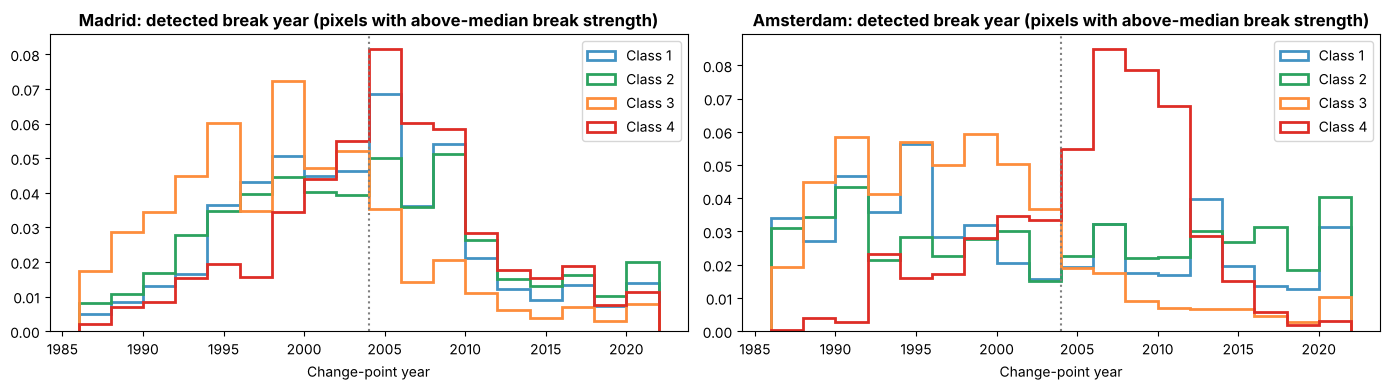

In [8]:
# ── Does the change-point year carry age information? ────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
bins = np.arange(1986, 2024, 2)
for ax, city in zip(axes, cubes):
    c = cubes[city]
    strong = c['F']['cp_strength'] > np.median(c['F']['cp_strength'])   # pixels with a clear break
    for cls in (1, 2, 3, 4):
        v = c['F']['cp_year'][(c['y'] == cls) & strong]
        ax.hist(v, bins=bins, histtype='step', lw=2, density=True, color=CLASS_COLORS[cls], label=f'Class {cls}')
    ax.axvline(2004, color='grey', ls=':')
    ax.set_title(f'{city}: detected break year (pixels with above-median break strength)', fontweight='bold')
    ax.set_xlabel('Change-point year'); ax.legend()
plt.tight_layout(); plt.show()

Class 4 breaks pile up after 2004 and class 3 breaks before it, in **both** cities — the change-point year is a
city-independent age signal, which is exactly the kind of feature that should transfer.

---

## 5.6 Spatial Context

Notebook 4's probability maps showed that even a weak model finds the right *districts*: whole neighbourhoods
were built in the same decade. A single pixel's spectrum is noisy, but its neighbours' spectra are extra evidence.

**DECISION** — for 24 key anomaly/change features we add the mean over building pixels in a square window of
radius *r* = 2, 6, 12 pixels (≈150 m block, ≈390 m neighbourhood, ≈750 m district), the local building density,
and a **local contrast** (pixel minus its neighbourhood) for 5 features, which flags infill buildings that differ
from their surroundings.

**No labels are used**, only the spectral features of neighbouring pixels, so there is no target leakage and the
same features can be computed for any new city from imagery alone. (A first version with 9 variables at
r = 2, 6 — kept as group `spatial_v1` — lifted Madrid CV from 0.680 to 0.729; this richer version reaches 0.771.)

In [9]:
V1_VARS = ['aNIR_mean', 'aSWIR1_mean', 'aNDVI_mean', 'aBlue_mean', 'aNDBI_mean',
           'cp_year', 'cp_strength', 'aNIR_slope', 'coverage']
V2_VARS = ['aNIR_mean', 'aSWIR1_mean', 'aSWIR2_mean', 'aNDVI_mean', 'aBlue_mean', 'aRed_mean',
           'aNDBI_mean', 'aBSI_mean', 'cp_year', 'cp_strength', 'cp_delta_NIR', 'cp_delta_SWIR1',
           'aNIR_slope', 'aNDVI_slope', 'aBlue_slope', 'aNIR_ep1984', 'aNIR_ep2000', 'aNIR_ep2016',
           'aNDVI_ep1984', 'aNDVI_ep2000', 'aNDVI_ep2016', 'coverage', 'aNIR_std', 'aBlue_std']
CONTRAST_VARS = ['aNIR_mean', 'aNDVI_mean', 'cp_year', 'aBlue_mean', 'coverage']

def neighbourhood_means(px, py, feats, radii, prefix):
    x, y = (px - px.min()).astype(int), (py - py.min()).astype(int)
    H, W = y.max() + 1, x.max() + 1
    occ = np.zeros((H, W), np.float32); occ[y, x] = 1
    out = {}
    for r in radii:
        s   = 2 * r + 1
        cnt = uniform_filter(occ, s, mode='constant')[y, x] * s * s     # building pixels in window
        out[f'{prefix}nb{r}_density'] = (cnt / (s * s)).astype(np.float32)
        for name, v in feats.items():
            g = np.zeros((H, W), np.float32); g[y, x] = v
            tot = uniform_filter(g, s, mode='constant')[y, x] * s * s
            out[f'{prefix}nb{r}_{name}'] = (tot / np.maximum(cnt, 1)).astype(np.float32)
    return out

for city, c in cubes.items():
    F = c['F']
    v1 = neighbourhood_means(c['px'], c['py'], {k: F[k] for k in V1_VARS}, (2, 6), '')
    v2 = neighbourhood_means(c['px'], c['py'], {k: F[k] for k in V2_VARS}, (2, 6, 12), 'v2_')
    for v in CONTRAST_VARS:
        for r in (2, 12):
            v2[f'v2_ctr{r}_{v}'] = F[v] - v2[f'v2_nb{r}_{v}']
    F.update(v1); F.update(v2)
    groups['spatial_v1'] = list(v1); groups['spatial'] = list(v2)
    print(f'{city}: spatial_v1={len(v1)}, spatial={len(v2)}')

Madrid: spatial_v1=20, spatial=85


Amsterdam: spatial_v1=20, spatial=85


### 5.6b Proof — buildings of one era really do cluster

The spatial features are only justified if a pixel's neighbours tend to share its age class. For every pixel we
measure the share of building pixels in its 5×5 window (r = 2, ≈150 m) that have the **same class**, and compare
it with what we would see if classes were scattered at random over the city (the sum of squared class shares).
Labels are used here **only to justify the decision**, never as model inputs.

In [10]:
def to_grid(c, values, fill=np.nan):
    # Place one value per pixel on the city's 30 m grid -> 2-D array for maps
    x, y = (c['px'] - c['px'].min()).astype(int), (c['py'] - c['py'].min()).astype(int)
    g = np.full((y.max() + 1, x.max() + 1), fill, dtype=np.float32)
    g[y, x] = values
    return g

clu_rows = []
for city, c in cubes.items():
    occ = to_grid(c, 1.0, 0.0)
    x, y = (c['px'] - c['px'].min()).astype(int), (c['py'] - c['py'].min()).astype(int)
    same = np.zeros(len(c['y']), np.float32)
    for r in (2, 6, 12):
        s = 2 * r + 1
        n_all = uniform_filter(occ, s, mode='constant')[y, x] * s * s - 1     # neighbours (minus itself)
        n_same = np.zeros_like(n_all)
        for k in (1, 2, 3, 4):
            g = to_grid(c, (c['y'] == k).astype(np.float32), 0.0)
            cnt = uniform_filter(g, s, mode='constant')[y, x] * s * s - 1
            n_same = np.where(c['y'] == k, cnt, n_same)
        ok = n_all > 0
        prior = np.bincount(c['y'], minlength=5)[1:] / len(c['y'])
        clu_rows.append({'city': city, 'window': f'r={r} (~{(2*r+1)*30} m)',
                         'same-class share of neighbours': (n_same[ok] / n_all[ok]).mean(),
                         'expected if random': (prior ** 2).sum()})
clu = pd.DataFrame(clu_rows).set_index(['city', 'window'])
clu['ratio'] = clu['same-class share of neighbours'] / clu['expected if random']
display(clu.style.format('{:.2f}'))

Neighbours share a pixel's class far more often than chance at every radius, and the effect fades slowly with
distance. Averaging the spectra of neighbours is therefore averaging over buildings that are mostly the same age,
which reduces noise without mixing eras. (The same clustering also makes random cross-validation optimistic; that is
measured with spatially blocked folds in Notebook 7.)

### 5.6c Maps — what the data and the features look like on the ground

Each pixel is drawn at its position on the 30 m grid. North is up.

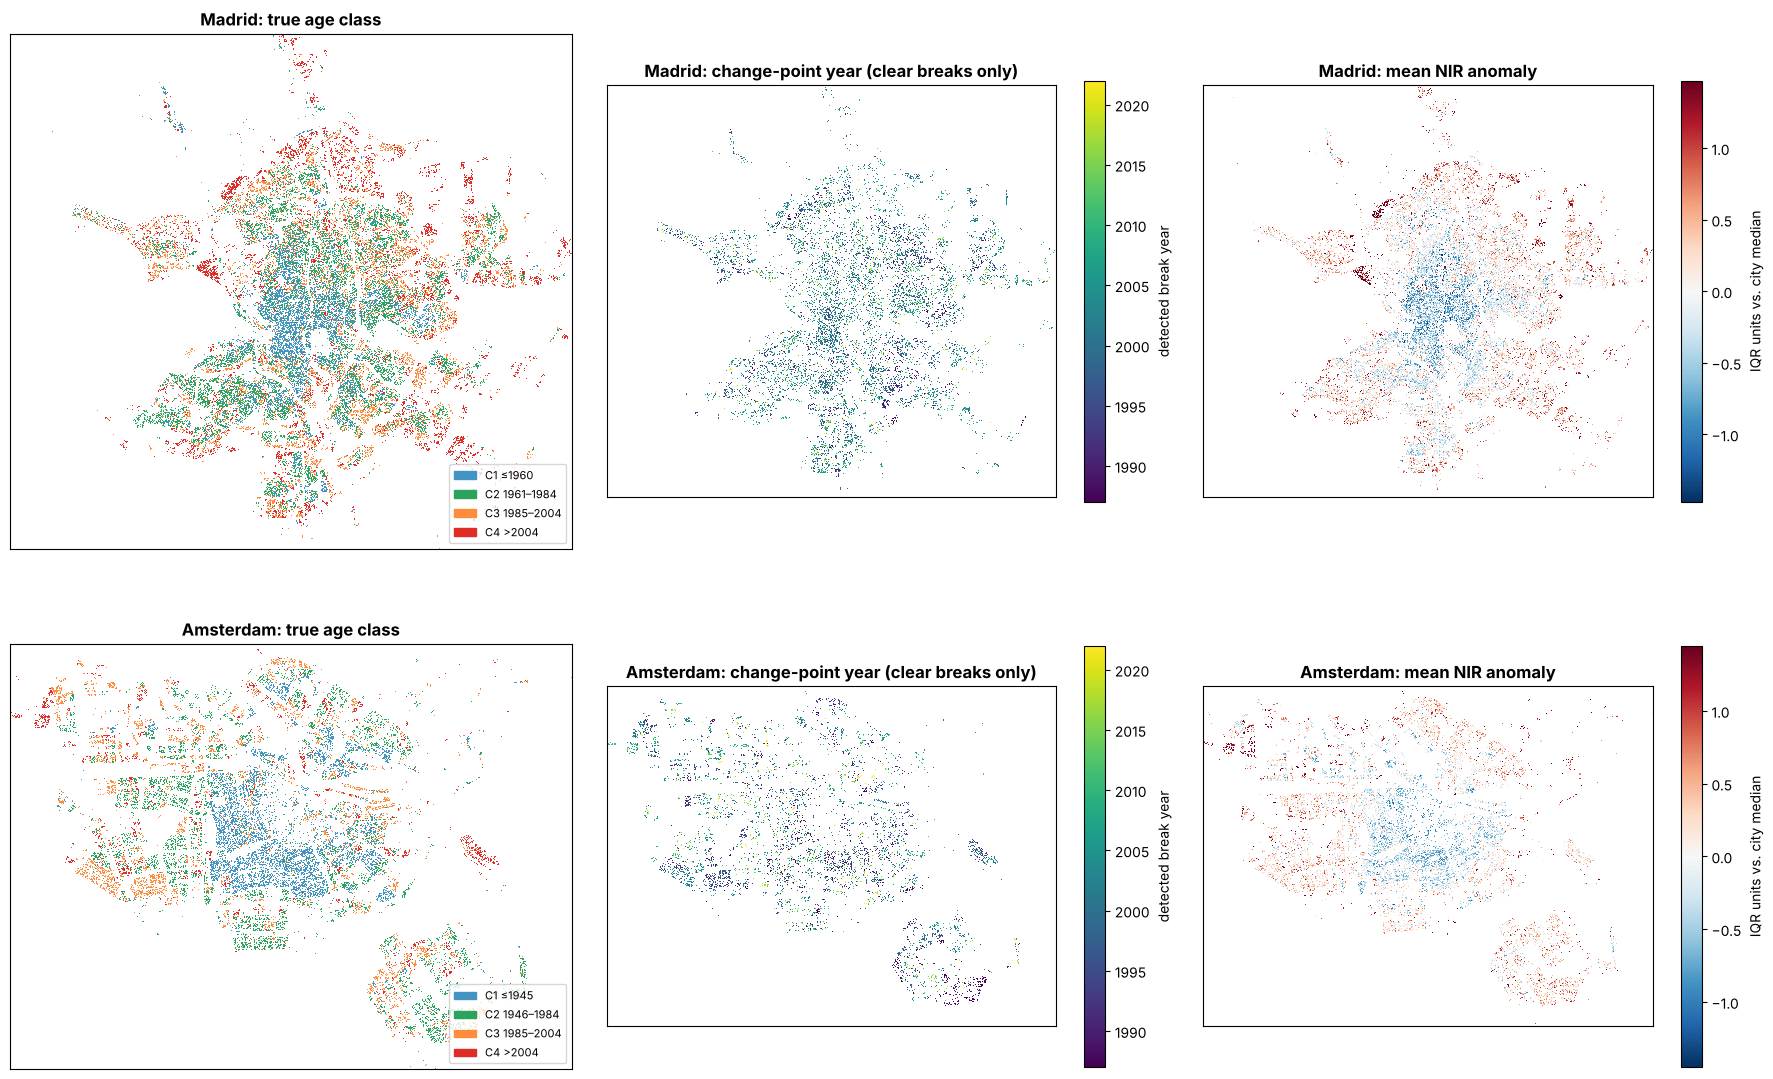

In [11]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch, Rectangle

cls_cmap = ListedColormap([CLASS_COLORS[k] for k in (1, 2, 3, 4)])
cls_norm = BoundaryNorm([0.5, 1.5, 2.5, 3.5, 4.5], 4)

def class_labels(city):
    e = CLASS_EVENTS[city]
    return {1: f'C1 ≤{e}', 2: f'C2 {e+1}–1984', 3: 'C3 1985–2004', 4: 'C4 >2004'}

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for row, (city, c) in zip(axes, cubes.items()):
    F = c['F']
    # (1) True age class
    row[0].imshow(to_grid(c, c['y']), cmap=cls_cmap, norm=cls_norm, origin='lower', interpolation='nearest')
    row[0].legend(handles=[Patch(color=CLASS_COLORS[k], label=v) for k, v in class_labels(city).items()],
                  loc='lower right', fontsize=8)
    row[0].set_title(f'{city}: true age class', fontweight='bold')
    # (2) Change-point year, only where the break is clear (above-median strength)
    strong = F['cp_strength'] > np.median(F['cp_strength'])
    im = row[1].imshow(to_grid(c, np.where(strong, F['cp_year'], np.nan)), cmap='viridis',
                       vmin=1987, vmax=2022, origin='lower', interpolation='nearest')
    plt.colorbar(im, ax=row[1], shrink=0.7, label='detected break year')
    row[1].set_title(f'{city}: change-point year (clear breaks only)', fontweight='bold')
    # (3) Mean NIR anomaly — the most important single spectral feature
    v = F['aNIR_mean']; lo, hi = np.percentile(v, [2, 98])
    im = row[2].imshow(to_grid(c, v), cmap='RdBu_r', vmin=-max(abs(lo), hi), vmax=max(abs(lo), hi),
                       origin='lower', interpolation='nearest')
    plt.colorbar(im, ax=row[2], shrink=0.7, label='IQR units vs. city median')
    row[2].set_title(f'{city}: mean NIR anomaly', fontweight='bold')
    for ax in row: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

* **Age-class maps:** old cores (class 1) sit in the centre and newer rings (classes 3 and 4) at the edge, in both
  cities. Classes form patches, not salt-and-pepper, which matches the clustering numbers above.
* **Change-point maps:** recent breaks (yellow) concentrate in the outer development areas that the label maps
  show as class 4. The break year is computed from imagery only, so this agreement is independent evidence that
  the feature measures construction timing.
* **NIR anomaly:** the same colour scale is meaningful in both cities because every value is relative to its own
  city and year.

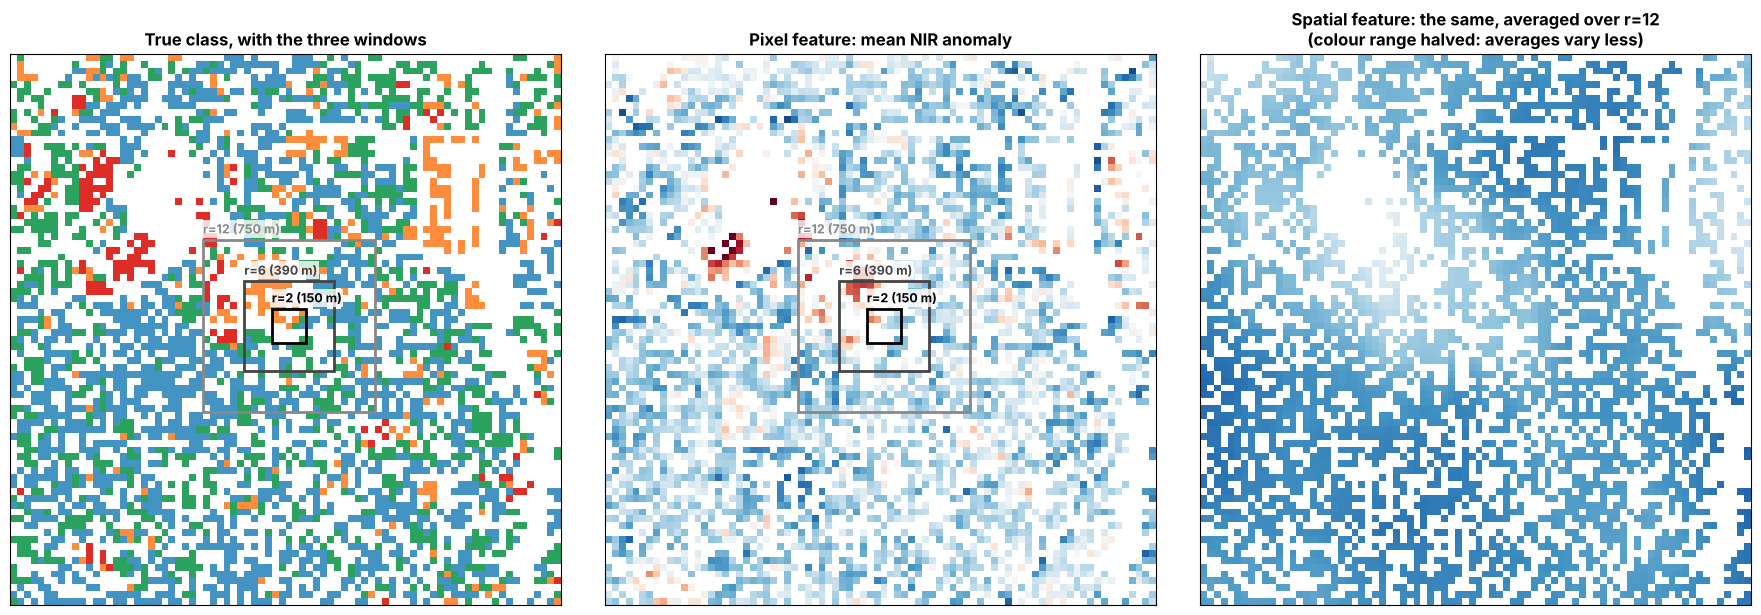

In [12]:
# ── How the neighbourhood windows look on a real patch (Madrid) ─────────────────
c = cubes['Madrid']
gy, gx = np.array(to_grid(c, c['y']).shape) // 2                     # centre of the city grid
half = 40
patch_cls  = to_grid(c, c['y'])[gy - half: gy + half, gx - half: gx + half]
patch_nir  = to_grid(c, c['F']['aNIR_mean'])[gy - half: gy + half, gx - half: gx + half]
patch_nb12 = to_grid(c, c['F']['v2_nb12_aNIR_mean'])[gy - half: gy + half, gx - half: gx + half]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(patch_cls, cmap=cls_cmap, norm=cls_norm, origin='lower', interpolation='nearest')
axes[1].imshow(patch_nir, cmap='RdBu_r', vmin=-2, vmax=2, origin='lower', interpolation='nearest')
axes[2].imshow(patch_nb12, cmap='RdBu_r', vmin=-1, vmax=1, origin='lower', interpolation='nearest')
for ax in axes[:2]:
    for r, col in [(2, 'black'), (6, '#444444'), (12, '#888888')]:
        ax.add_patch(Rectangle((half - r - 0.5, half - r - 0.5), 2 * r + 1, 2 * r + 1, fill=False, lw=2, ec=col))
        ax.text(half - r - 0.5, half + r + 1.0, f'r={r} ({(2*r+1)*30} m)', fontsize=9, color=col, fontweight='bold',
                ha='left', va='bottom', bbox=dict(fc='white', ec='none', alpha=0.8, pad=1))
axes[0].set_title('True class, with the three windows', fontweight='bold')
axes[1].set_title('Pixel feature: mean NIR anomaly', fontweight='bold')
axes[2].set_title('Spatial feature: the same, averaged over r=12\n(colour range halved: averages vary less)', fontweight='bold')
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

The window at r = 12 (750 m) smooths single-pixel noise into district-level patterns that follow the class
patches in the left panel. Each pixel receives the averages of its own three windows as extra features.

---

## 5.7 Assemble & Save

One row per pixel. Metadata columns (`px_key`, `py_key`, `weighted_mean_year`, `age_class`, `city`) are kept
separate from features. Standardisation is **not** done here: it is done per city in Notebook 6
(Section 6.2), because a scaler fit on Madrid and applied to Amsterdam (Notebook 3's approach) carries Madrid's
scale into Amsterdam — the opposite of what transfer needs.

In [13]:
for city, c in cubes.items():
    meta = pd.DataFrame({'px_key': c['px'], 'py_key': c['py'], 'weighted_mean_year': c['wmy'],
                         'age_class': c['y'], 'city': city})
    X = pd.DataFrame({k: np.asarray(v, np.float32) for k, v in c['F'].items()})
    df = pd.concat([meta, X], axis=1)
    n_nan = int(X.isna().sum().sum())
    assert n_nan == 0, f'{city}: {n_nan} NaN values'
    out = FEAT_DIR / f'features_{city.lower()}.parquet'
    df.to_parquet(out)
    print(f'{city:10s}: {df.shape[0]:,} pixels x {X.shape[1]} features -> {out}')

json.dump(groups, open(FEAT_DIR / 'feature_groups.json', 'w'), indent=1)
print({g: len(v) for g, v in groups.items()})

Madrid    : 76,263 pixels x 284 features -> data/features/features_madrid.parquet


Amsterdam : 25,992 pixels x 284 features -> data/features/features_amsterdam.parquet
{'baseline': 60, 'anomaly': 99, 'change': 17, 'meta': 3, 'spatial_v1': 20, 'spatial': 85}


---

## 5.8 Summary

1. **Cube** — one dense `pixel × year × band` array per city; per-slot haze filtering and median compositing
   recover clean observations that Notebook 3 discarded.
2. **City-year anomalies** remove sensor, atmosphere and city-wide colour differences, so features mean the same
   thing in every city.
3. **Temporal features** describe *when* a pixel changed (epoch means, slope, change-point year, largest jump),
   which directly targets the 1984 / 2004 class boundaries.
4. **Spatial context** adds what the surrounding neighbourhood looks like, using imagery only — never labels.
5. Features are saved **unstandardised**; per-city standardisation happens in Notebook 6.

**Next:** Notebook 6 trains the Stage 1 (Madrid) model and the Stage 2 (Amsterdam) few-shot transfer procedure.